# EDA: Urbanization vs. Emissions
Proposition: *Countries are getting worse on emissions as they urbanize.*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
df = pd.read_csv('climate-change.csv')
df.columns = [c.replace('average_value_', '') for c in df.columns]
df.shape

(16165, 53)

In [2]:
df.isna().mean().sort_values().round(2)

Country Name                                                                                  0.00
Country Code                                                                                  0.00
Year                                                                                          0.00
Population, total                                                                             0.00
Urban population (% of total population)                                                      0.01
Urban population                                                                              0.01
Population growth (annual %)                                                                  0.02
Urban population growth (annual %)                                                            0.03
Agricultural land (sq. km)                                                                    0.14
Agricultural land (% of land area)                                                            0.15
Arable lan

## Setup
The dataset mixes countries with World Bank aggregates (regions, income groups), so split them.

In [3]:
AGG = {'AFE','AFW','ARB','CEB','CSS','EAP','EAR','EAS','ECA','ECS','EMU','EUU','FCS','HIC','HPC','IBD','IBT',
       'IDA','IDB','IDX','INX','LAC','LCN','LDC','LIC','LMC','LMY','LTE','MEA','MIC','MNA','NAC','OED','OSS',
       'PRE','PSS','PST','SAS','SSA','SSF','SST','TEA','TEC','TLA','TMN','TSA','TSS','UMC','WLD'}

U = 'Urban population (% of total population)'
C = 'CO2 emissions (metric tons per capita)'
K = 'CO2 emissions (kt)'
I = 'CO2 emissions (kg per 2010 US$ of GDP)'
R = 'Renewable energy consumption (% of total final energy consumption)'

cty = df[~df['Country Code'].isin(AGG)]
agg = df[df['Country Code'].isin(AGG)]
print('countries:', cty['Country Code'].nunique(), '| aggregates:', agg['Country Code'].nunique())
for col in [U, C, K, I, R]:
    yrs = df.loc[df[col].notna(), 'Year']
    print(f'{col}: {yrs.min()}-{yrs.max()}')

countries: 217 | aggregates: 48
Urban population (% of total population): 1960-2020
CO2 emissions (metric tons per capita): 1960-2018
CO2 emissions (kt): 1960-2018
CO2 emissions (kg per 2010 US$ of GDP): 1960-2018
Renewable energy consumption (% of total final energy consumption): 1990-2018


## World trend

In [4]:
world = df[df['Country Code'] == 'WLD'].sort_values('Year').set_index('Year')[[U, C, K, I, R]]
world.loc[::5]

,Urban population (% of total population),CO2 emissions (metric tons per capita),CO2 emissions (kt),CO2 emissions (kg per 2010 US$ of GDP),Renewable energy consumption (% of total final energy consumption)
Year,,,,,
1960,33.617972,3.121158,9.463838e+06,0.836009,NaN
1965,35.556682,3.432395,1.140258e+07,0.772025,NaN
1970,36.554352,4.147851,1.527229e+07,0.800447,NaN
1975,37.685495,4.342629,1.764196e+07,0.765921,NaN
1980,39.349663,4.601082,2.039643e+07,0.732549,NaN
1985,41.216987,4.428312,2.142938e+07,0.677553,NaN
1990,43.028730,3.902964,2.060783e+07,0.543632,17.067154
1995,44.842067,3.781982,2.158284e+07,0.511988,17.755348
2000,46.689322,3.812649,2.331181e+07,0.466241,17.854914


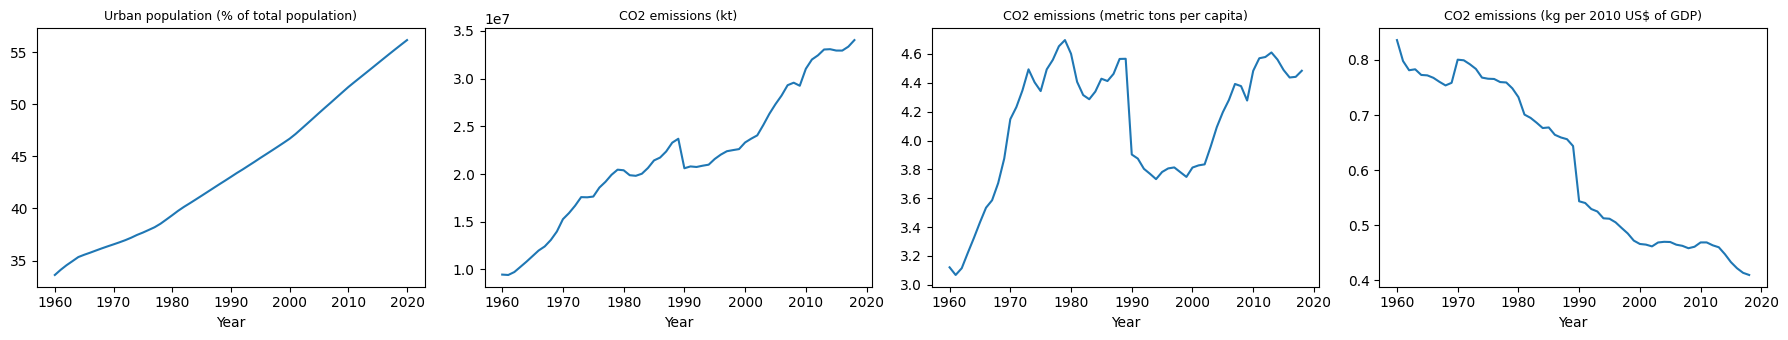

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, col in zip(axes, [U, K, C, I]):
    world[col].dropna().plot(ax=ax)
    ax.set_title(col, fontsize=9)
plt.tight_layout()

## Cross-sectional: urban % vs CO2 per capita

In [6]:
for y in [1990, 2000, 2010, 2014]:
    s = cty[cty.Year == y][[U, C]].dropna()
    print(y, 'n =', len(s),
          '| pearson', round(s.corr().iloc[0, 1], 2),
          '| spearman', round(s.corr('spearman').iloc[0, 1], 2),
          '| log CO2', round(np.corrcoef(s[U], np.log(s[C].clip(0.01)))[0, 1], 2))

1990 n = 190 | pearson 0.63 | spearman 0.75 | log CO2 0.71
2000 n = 191 | pearson 0.64 | spearman 0.77 | log CO2 0.74
2010 n = 191 | pearson 0.6 | spearman 0.72 | log CO2 0.72
2014 n = 190 | pearson 0.58 | spearman 0.71 | log CO2 0.7


In [7]:
s = cty[cty.Year == 2014][['Country Name', U, C, I, R]].dropna(subset=[U, C])
s['bin'] = pd.cut(s[U], [0, 20, 40, 60, 80, 100])
s.groupby('bin', observed=True)[[C, I, R]].median().round(2)

,CO2 emissions (metric tons per capita),CO2 emissions (kg per 2010 US$ of GDP),Renewable energy consumption (% of total final energy consumption)
bin,,,
"(0, 20]",0.20,0.23,67.70
"(20, 40]",0.58,0.35,47.22
"(40, 60]",1.76,0.39,31.34
"(60, 80]",4.12,0.43,14.02
"(80, 100]",7.45,0.25,7.36


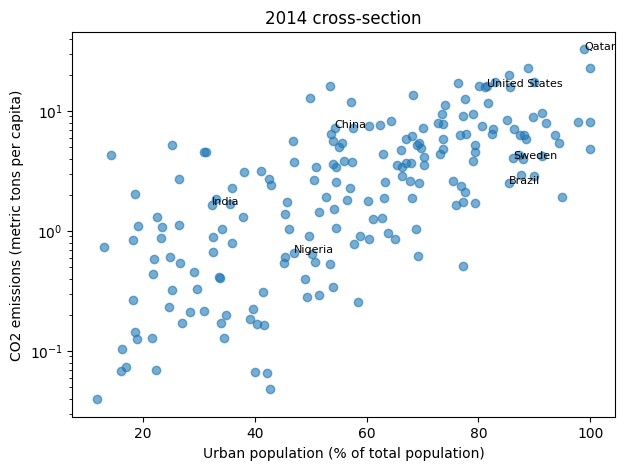

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(s[U], s[C], alpha=0.6)
ax.set_yscale('log')
ax.set_xlabel(U); ax.set_ylabel(C)
ax.set_title('2014 cross-section')
for _, r in s[s['Country Name'].isin(['China', 'India', 'United States', 'Qatar', 'Sweden', 'Nigeria', 'Brazil'])].iterrows():
    ax.annotate(r['Country Name'], (r[U], r[C]), fontsize=8)

## Within-country change, 1990 → 2018

In [9]:
a = cty[cty.Year == 1990].set_index('Country Name')[[U, C, I]]
b = cty[cty.Year == 2018].set_index('Country Name')[[U, C, I]]
d = (b - a).dropna()
d.columns = ['dU', 'dC', 'dI']
d['U90'], d['C90'] = a[U], a[C]
d['pctC'] = d.dC / d.C90 * 100

print('countries:', len(d), '| urbanized:', (d.dU > 0).sum())
print('urbanizers with CO2pc up:', ((d.dU > 0) & (d.dC > 0)).sum(), '| down:', ((d.dU > 0) & (d.dC < 0)).sum())
print('carbon intensity fell:', (d.dI < 0).sum(), 'of', len(d))
print('corr(dU, dC):', round(d.dU.corr(d.dC), 2))

countries: 157 | urbanized: 134
urbanizers with CO2pc up: 92 | down: 42
carbon intensity fell: 92 of 157
corr(dU, dC): 0.29


In [10]:
d['group'] = pd.cut(d.U90, [0, 40, 70, 100], labels=['<40% urban in 1990', '40-70%', '>70%'])
d.groupby('group', observed=True)[['dU', 'dC', 'pctC', 'dI']].median().round(2)

,dU,dC,pctC,dI
group,,,,
<40% urban in 1990,10.28,0.17,81.30,0.04
40-70%,9.95,0.70,33.88,-0.08
>70%,4.93,-1.34,-16.81,-0.11


In [11]:
d.sort_values('dU', ascending=False).head(12).round(2)

,dU,dC,dI,U90,C90,pctC,group
Country Name,,,,,,,
Equatorial Guinea,37.40,4.95,0.23,34.74,0.14,3460.04,<40% urban in 1990
China,32.71,5.49,-1.68,26.44,1.91,286.79,<40% urban in 1990
Costa Rica,29.34,0.73,-0.03,50.00,0.92,79.58,40-70%
Angola,28.37,0.35,0.08,37.14,0.53,66.10,<40% urban in 1990
Botswana,27.51,1.46,-0.07,41.93,2.18,66.79,40-70%
Haiti,26.77,0.15,0.13,28.51,0.14,106.57,<40% urban in 1990
Malaysia,26.24,4.48,-0.06,49.79,3.12,143.87,40-70%
Dominican Republic,25.85,1.26,-0.10,55.23,1.10,114.53,40-70%
Indonesia,24.74,1.36,0.03,30.58,0.82,167.05,<40% urban in 1990


Demeaning by country removes the between-country (income) effect, leaving only how urban % and CO2 co-move over time within each country.

within-country demeaned corr: 0.17
share of countries with negative corr: 0.32


C:\Users\email\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\email\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


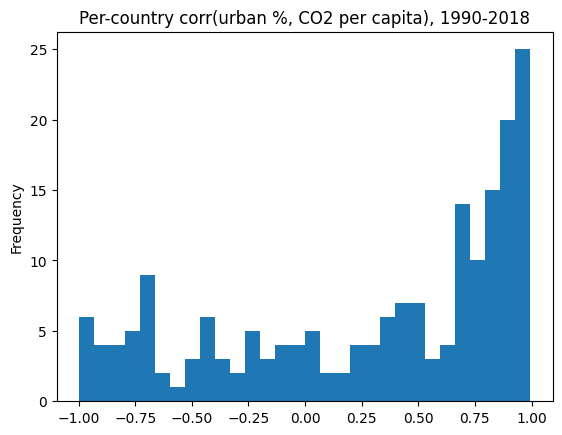

In [12]:
p = cty[cty.Year >= 1990][['Country Name', 'Year', U, C]].dropna()
dm = p.groupby('Country Name')[[U, C]].transform(lambda x: x - x.mean())
print('within-country demeaned corr:', round(dm[U].corr(dm[C]), 2))

per_country = p.groupby('Country Name')[[U, C]].apply(lambda g: g[U].corr(g[C])).dropna()
print('share of countries with negative corr:', round((per_country < 0).mean(), 2))
per_country.plot.hist(bins=30, title='Per-country corr(urban %, CO2 per capita), 1990-2018');

## Country trajectories

In [13]:
names = ['United States', 'United Kingdom', 'Germany', 'France', 'Japan', 'Korea, Rep.', 'China', 'India',
         'Brazil', 'Indonesia', 'Nigeria', 'Denmark', 'Sweden', 'Saudi Arabia', 'Vietnam']
rows = []
for name in names:
    t = cty[cty['Country Name'] == name].set_index('Year')
    row = {'country': name, 'peak_CO2_year': t[C].idxmax()}
    for y in [1970, 1990, 2005, 2018]:
        row[f'U{y}'] = round(t[U].get(y, np.nan), 0)
        row[f'C{y}'] = round(t[C].get(y, np.nan), 1)
    rows.append(row)
pd.DataFrame(rows).set_index('country')

,peak_CO2_year,U1970,C1970,U1990,C1990,U2005,C2005,U2018,C2018
country,,,,,,,,,
United States,1973,74.0,21.1,75.0,19.4,80.0,19.5,82.0,15.2
United Kingdom,1971,77.0,11.7,78.0,9.7,80.0,9.0,83.0,5.4
Germany,1990,72.0,NaN,73.0,12.0,76.0,9.7,77.0,8.6
France,1973,71.0,8.4,74.0,6.1,77.0,6.0,80.0,4.6
Japan,2013,72.0,7.4,77.0,8.8,86.0,9.5,92.0,8.7
"Korea, Rep.",2018,41.0,1.7,74.0,5.8,81.0,10.0,81.0,12.2
China,2018,17.0,0.9,26.0,1.9,43.0,4.5,59.0,7.4
India,2018,20.0,0.4,26.0,0.6,29.0,1.0,34.0,1.8
Brazil,2014,56.0,1.0,74.0,1.3,83.0,1.8,87.0,2.0


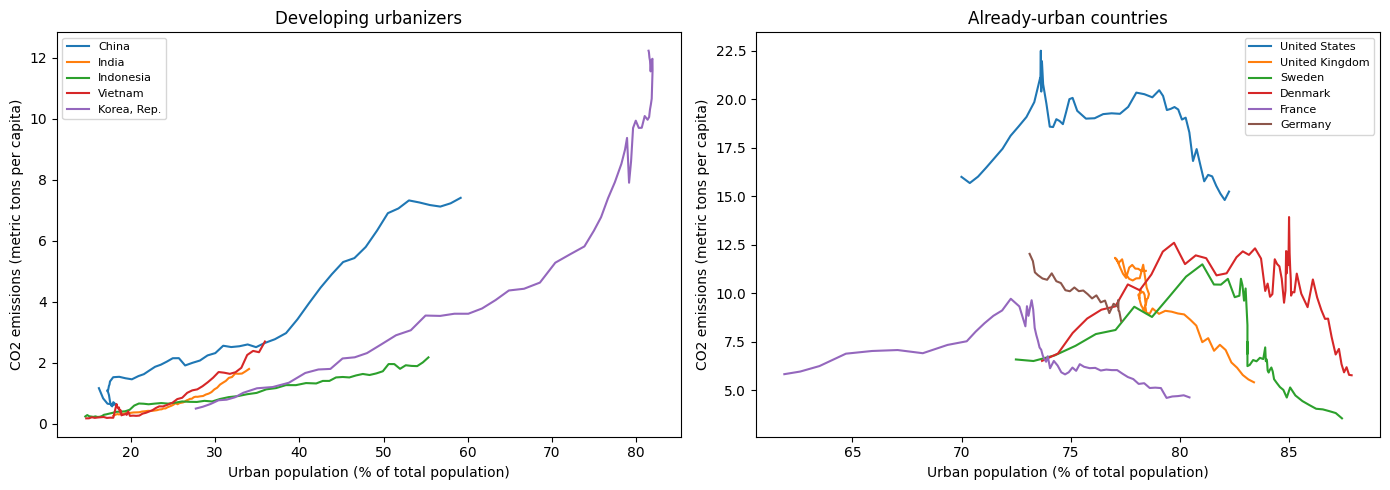

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
groups = [['China', 'India', 'Indonesia', 'Vietnam', 'Korea, Rep.'],
          ['United States', 'United Kingdom', 'Sweden', 'Denmark', 'France', 'Germany']]
for ax, grp, title in zip(axes, groups, ['Developing urbanizers', 'Already-urban countries']):
    for name in grp:
        t = cty[cty['Country Name'] == name].sort_values('Year')[[U, C]].dropna()
        ax.plot(t[U], t[C], label=name)
    ax.set_xlabel(U); ax.set_ylabel(C); ax.set_title(title); ax.legend(fontsize=8)
plt.tight_layout()

## Income-group aggregates

In [15]:
rows = []
for code_ in ['WLD', 'HIC', 'UMC', 'LMC', 'LIC']:
    t = df[df['Country Code'] == code_].set_index('Year')
    for y in [1990, 2005, 2018]:
        rows.append({'group': code_, 'year': y, 'urban %': t.at[y, U], 'CO2 pc': t.at[y, C],
                     'CO2 Mkt': t.at[y, K] / 1e6, 'intensity': t.at[y, I], 'renewable %': t.at[y, R]})
pd.DataFrame(rows).set_index(['group', 'year']).round(2)

urban %  CO2 pc  CO2 Mkt  intensity  renewable %
group year                                                  
WLD   1990    43.03    3.90    20.61       0.54        17.07
      2005    49.15    4.20    27.33       0.47        16.92
      2018    55.27    4.48    34.04       0.41          NaN
HIC   1990    74.31   11.44    11.46       0.39         6.41
      2005    78.51   12.05    13.40       0.31         7.67
      2018    81.38   10.25    12.37       0.23          NaN
UMC   1990    42.36    3.37     6.59       1.09        19.58
      2005    54.19    4.50    10.21       0.95        16.28
      2018    65.99    6.26    15.57       0.72          NaN
LMC   1990    30.39    1.10     2.21       1.01        43.61
      2005    35.67    1.23     3.26       0.83        40.69
      2018    41.46    1.73     5.61       0.73          NaN
LIC   1990    24.48    0.65     0.19       1.16        59.67
      2005    28.52    0.44     0.20       0.70        67.69
      2018    32.58    0.24     0.15       0.29          NaN

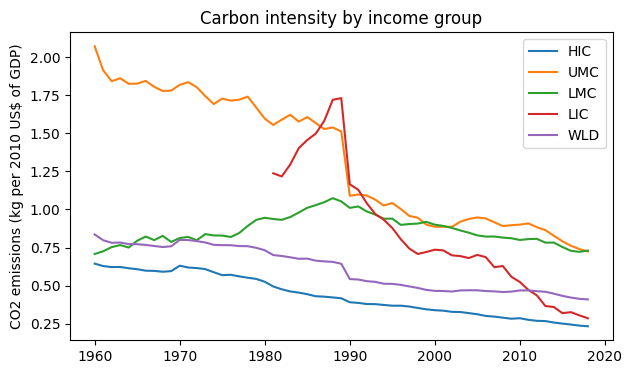

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
for code_ in ['HIC', 'UMC', 'LMC', 'LIC', 'WLD']:
    t = df[df['Country Code'] == code_].sort_values('Year').set_index('Year')[I].dropna()
    ax.plot(t.index, t.values, label=code_)
ax.set_ylabel(I); ax.set_title('Carbon intensity by income group'); ax.legend();

# Draft persuasive visualizations
Two per side. Figures are saved to `figures/`.

In [17]:
import os
os.makedirs('figures', exist_ok=True)

SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
INK, INK2, MUTED, GRID = '#0b0b0b', '#52514e', '#8a8984', '#e4e3df'

plt.rcParams.update({
    'font.family': 'sans-serif', 'font.size': 11, 'axes.edgecolor': MUTED, 'axes.labelcolor': INK2,
    'xtick.color': INK2, 'ytick.color': INK2, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'figure.facecolor': 'white', 'axes.titlelocation': 'left', 'axes.titleweight': 'bold',
})

def series(code_, col, start=1960, end=2018):
    t = df[df['Country Code'] == code_].set_index('Year').sort_index()[col]
    return t.loc[start:end].dropna()

def country(name, col, start=1960, end=2018):
    t = cty[cty['Country Name'] == name].set_index('Year').sort_index()[col]
    return t.loc[start:end].dropna()

SOURCE = 'Source: World Bank, World Development Indicators'

## TRUE 1: World urbanization and total CO2 move together
Dual axis with both scales chosen so the lines overlap; total kt (not per capita) so population growth inflates the rise; window starts in 1990 to skip the 1970s–80s plateau.

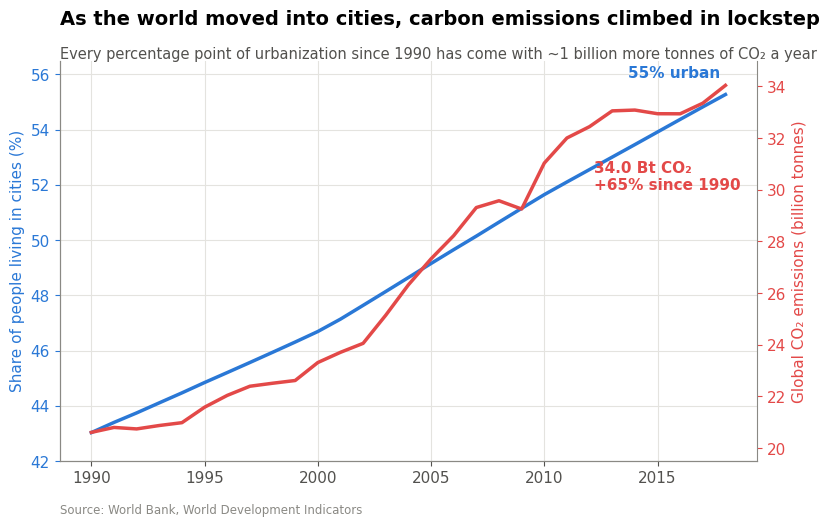

In [18]:
urb, co2 = series('WLD', U, 1990), series('WLD', K, 1990) / 1e6

fig, ax1 = plt.subplots(figsize=(9, 5.2))
ax2 = ax1.twinx()
ax1.plot(urb.index, urb.values, color=SERIES[0], lw=2.5)
ax2.plot(co2.index, co2.values, color=SERIES[7], lw=2.5)
ax1.set_ylim(42, 56.5)
ax2.set_ylim(19.5, 35)
ax2.spines['right'].set_visible(True)
ax2.grid(False)
ax1.set_ylabel('Share of people living in cities (%)', color=SERIES[0])
ax2.set_ylabel('Global CO\u2082 emissions (billion tonnes)', color=SERIES[7])
ax1.tick_params(axis='y', colors=SERIES[0]); ax2.tick_params(axis='y', colors=SERIES[7])

ax1.annotate(f'{urb.iloc[-1]:.0f}% urban', (urb.index[-1], urb.iloc[-1]), xytext=(-70, 12),
             textcoords='offset points', color=SERIES[0], fontweight='bold')
ax2.annotate(f'{co2.iloc[-1]:.1f} Bt CO\u2082\n+{(co2.iloc[-1] / co2.iloc[0] - 1) * 100:.0f}% since 1990',
             (co2.index[-1], co2.iloc[-1]), xytext=(-95, -75), textcoords='offset points',
             color=SERIES[7], fontweight='bold')

ax1.set_title('As the world moved into cities, carbon emissions climbed in lockstep', fontsize=14, pad=26)
fig.text(0.125, 0.885, 'Every percentage point of urbanization since 1990 has come with ~1 billion more tonnes of CO\u2082 a year',
         color=INK2, fontsize=10.5)
fig.text(0.125, 0.01, SOURCE, color=MUTED, fontsize=8.5)
fig.savefig('figures/true1_world_lockstep.png', dpi=200, bbox_inches='tight')

## TRUE 2: Fast urbanizers' emissions explode
Connected scatter, only countries that urbanized fast *and* grew emissions; per-capita % change in labels makes small absolute bases look huge.

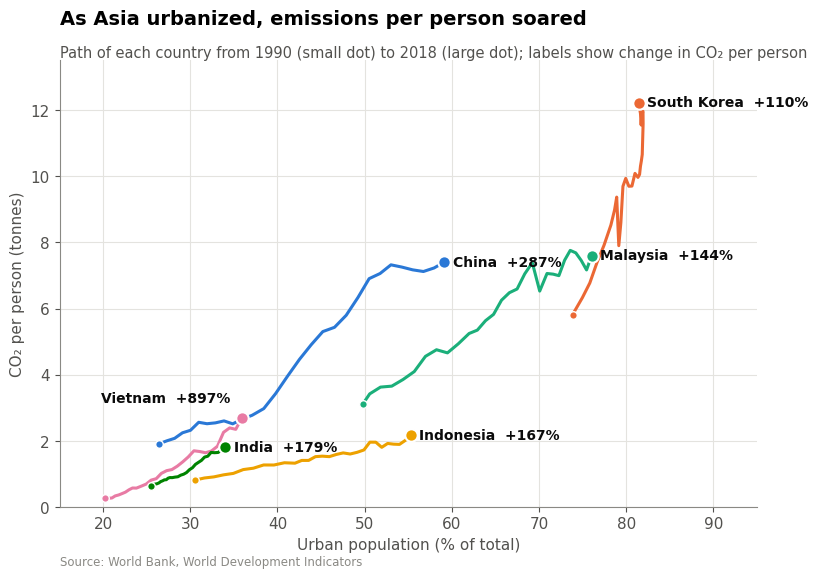

In [19]:
picks = ['China', 'Korea, Rep.', 'Malaysia', 'Indonesia', 'Vietnam', 'India']

fig, ax = plt.subplots(figsize=(9, 5.8))
for i, name in enumerate(picks):
    u, c = country(name, U, 1990), country(name, C, 1990)
    t = pd.concat([u, c], axis=1, join='inner')
    col = SERIES[i]
    ax.plot(t[U], t[C], color=col, lw=2.2)
    ax.scatter(t[U].iloc[0], t[C].iloc[0], color=col, s=30, zorder=3, edgecolor='white')
    ax.scatter(t[U].iloc[-1], t[C].iloc[-1], color=col, s=80, zorder=3, edgecolor='white', linewidth=1.5)
    pct = (t[C].iloc[-1] / t[C].iloc[0] - 1) * 100
    label = 'South Korea' if name == 'Korea, Rep.' else name
    xy, ha = ((-8, 14), 'right') if name == 'Vietnam' else ((6, 0), 'left')
    ax.annotate(f'{label}  +{pct:.0f}%', (t[U].iloc[-1], t[C].iloc[-1]), xytext=xy, ha=ha,
                textcoords='offset points', color=INK, fontsize=10, va='center', fontweight='bold')

ax.set_xlim(15, 95); ax.set_ylim(0, 13.5)
ax.set_xlabel('Urban population (% of total)')
ax.set_ylabel('CO\u2082 per person (tonnes)')
ax.set_title('As Asia urbanized, emissions per person soared', fontsize=14, pad=26)
fig.text(0.125, 0.885, 'Path of each country from 1990 (small dot) to 2018 (large dot); labels show change in CO\u2082 per person',
         color=INK2, fontsize=10.5)
fig.text(0.125, 0.01, SOURCE, color=MUTED, fontsize=8.5)
fig.savefig('figures/true2_asia_paths.png', dpi=200, bbox_inches='tight')

## TRUE 3: Same countries, common starting point
Every path starts at the origin: x = urban percentage points gained since 1990, y = change in CO2 per person since 1990, so slopes and endpoints compare directly.

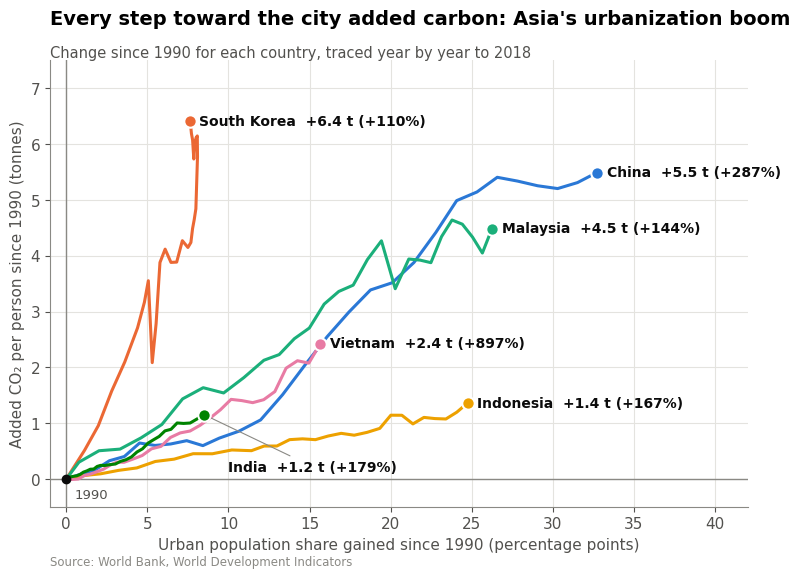

In [20]:
picks = ['China', 'Korea, Rep.', 'Malaysia', 'Indonesia', 'Vietnam', 'India']

fig, ax = plt.subplots(figsize=(9, 5.8))
ax.axhline(0, color=MUTED, lw=1)
ax.axvline(0, color=MUTED, lw=1)
for i, name in enumerate(picks):
    t = pd.concat([country(name, U, 1990), country(name, C, 1990)], axis=1, join='inner')
    du, dc = t[U] - t[U].iloc[0], t[C] - t[C].iloc[0]
    col = SERIES[i]
    ax.plot(du, dc, color=col, lw=2.2)
    ax.scatter(du.iloc[-1], dc.iloc[-1], color=col, s=80, zorder=3, edgecolor='white', linewidth=1.5)
    pct = (t[C].iloc[-1] / t[C].iloc[0] - 1) * 100
    label = 'South Korea' if name == 'Korea, Rep.' else name
    text = f'{label}  +{dc.iloc[-1]:.1f} t (+{pct:.0f}%)'
    if name == 'India':
        ax.annotate(text, (du.iloc[-1], dc.iloc[-1]), xytext=(10, 0.22), color=INK, fontsize=10, va='center',
                    fontweight='bold', arrowprops=dict(arrowstyle='-', color=MUTED, lw=0.8, shrinkB=6))
    else:
        ax.annotate(text, (du.iloc[-1], dc.iloc[-1]), xytext=(7, 0), textcoords='offset points',
                    color=INK, fontsize=10, va='center', fontweight='bold')
ax.scatter(0, 0, color=INK, s=36, zorder=4)
ax.annotate('1990', (0, 0), xytext=(6, -14), textcoords='offset points', color=INK2, fontsize=9.5)

ax.set_xlim(-1, 42); ax.set_ylim(-0.5, 7.5)
ax.set_xlabel('Urban population share gained since 1990 (percentage points)')
ax.set_ylabel('Added CO₂ per person since 1990 (tonnes)')
ax.set_title("Every step toward the city added carbon: Asia's urbanization boom", fontsize=14, pad=26)
fig.text(0.125, 0.885, 'Change since 1990 for each country, traced year by year to 2018',
         color=INK2, fontsize=10.5)
fig.text(0.125, 0.01, SOURCE, color=MUTED, fontsize=8.5)
fig.savefig('figures/true3_asia_common_start.png', dpi=200, bbox_inches='tight')

## FALSE 1: Urban countries keep urbanizing while cutting emissions
Small multiples, both measures indexed to 1990 = 100 on one shared axis; only already-urban rich countries shown.

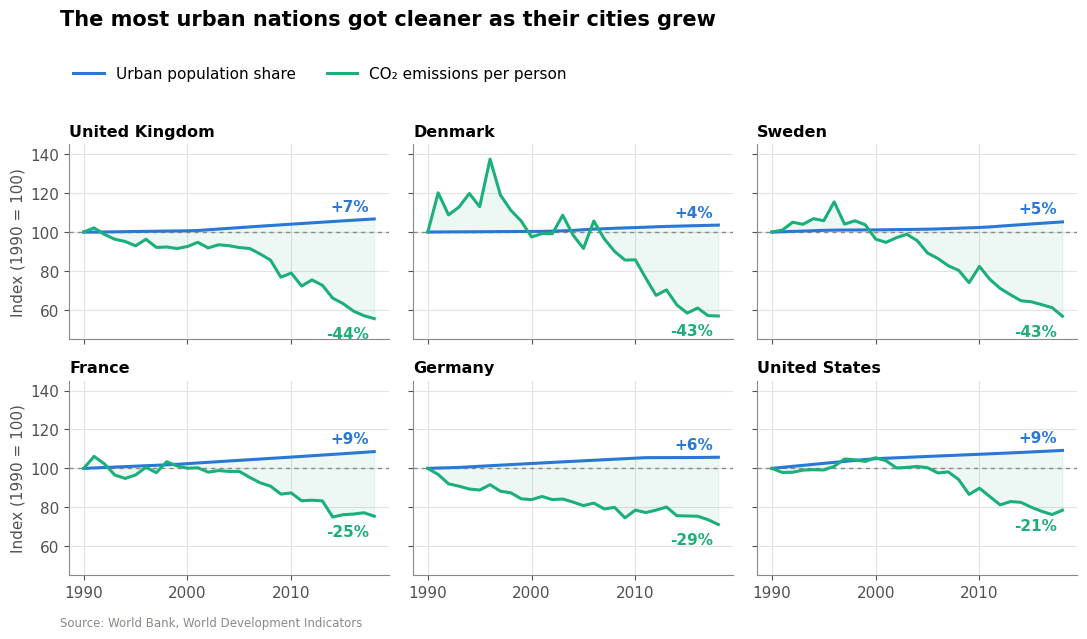

In [21]:
picks = ['United Kingdom', 'Denmark', 'Sweden', 'France', 'Germany', 'United States']

fig, axes = plt.subplots(2, 3, figsize=(11, 6.2), sharex=True, sharey=True)
for ax, name in zip(axes.flat, picks):
    u, c = country(name, U, 1990), country(name, C, 1990)
    ui, ci = u / u.iloc[0] * 100, c / c.iloc[0] * 100
    ax.axhline(100, color=MUTED, lw=1, ls=(0, (3, 3)))
    ax.plot(ui.index, ui.values, color=SERIES[0], lw=2.2)
    ax.plot(ci.index, ci.values, color=SERIES[2], lw=2.2)
    ax.fill_between(ci.index, ci.values, ui.values, color=SERIES[2], alpha=0.08)
    ax.set_title(name, fontsize=11.5)
    ax.annotate(f'{ci.iloc[-1] - 100:+.0f}%', (ci.index[-1], ci.iloc[-1]), xytext=(-4, -14),
                textcoords='offset points', ha='right', color=SERIES[2], fontweight='bold')
    ax.annotate(f'{ui.iloc[-1] - 100:+.0f}%', (ui.index[-1], ui.iloc[-1]), xytext=(-4, 6),
                textcoords='offset points', ha='right', color=SERIES[0], fontweight='bold')
ax.set_ylim(45, 145)
for ax in axes[:, 0]:
    ax.set_ylabel('Index (1990 = 100)')

handles = [plt.Line2D([], [], color=SERIES[0], lw=2.2), plt.Line2D([], [], color=SERIES[2], lw=2.2)]
fig.legend(handles, ['Urban population share', 'CO\u2082 emissions per person'], loc='upper left',
           bbox_to_anchor=(0.06, 0.93), ncol=2, frameon=False)
fig.suptitle('The most urban nations got cleaner as their cities grew', x=0.06, ha='left',
             fontsize=15, fontweight='bold', y=1.0)
fig.text(0.06, 0.005, SOURCE, color=MUTED, fontsize=8.5)
fig.tight_layout(rect=(0, 0.02, 1, 0.9))
fig.savefig('figures/false1_urban_decoupling.png', dpi=200, bbox_inches='tight')

## FALSE 2: Carbon intensity is falling at every stage of urbanization
CO2 per $ of GDP (not per person or total), income groups relabeled by their urbanization level.

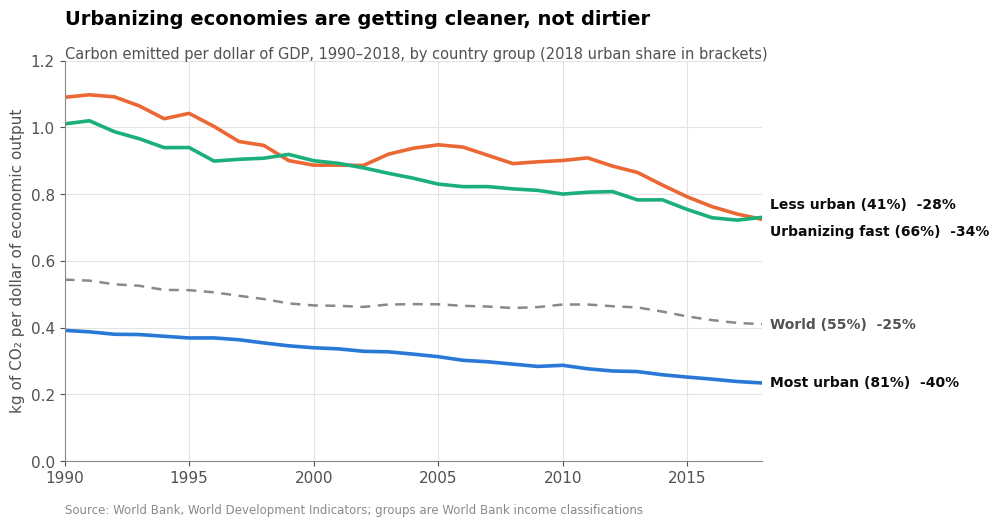

In [22]:
groups = [('HIC', 'Most urban (81%)'), ('UMC', 'Urbanizing fast (66%)'),
          ('LMC', 'Less urban (41%)'), ('WLD', 'World (55%)')]

fig, ax = plt.subplots(figsize=(9, 5.2))
for i, (code_, label) in enumerate(groups):
    t = series(code_, I, 1990)
    col = MUTED if code_ == 'WLD' else SERIES[i]
    ax.plot(t.index, t.values, color=col, lw=2.6 if code_ != 'WLD' else 1.8,
            ls='-' if code_ != 'WLD' else (0, (4, 3)))
    pct = (t.iloc[-1] / t.iloc[0] - 1) * 100
    dy = {'UMC': -9, 'LMC': 9}.get(code_, 0)
    ax.annotate(f'{label}  {pct:.0f}%', (t.index[-1], t.iloc[-1]), xytext=(6, dy), textcoords='offset points',
                va='center', color=INK if code_ != 'WLD' else INK2, fontsize=10, fontweight='bold')

ax.set_ylim(0, 1.2)
ax.set_xlim(1990, 2018)
ax.set_ylabel('kg of CO\u2082 per dollar of economic output')
ax.set_title('Urbanizing economies are getting cleaner, not dirtier', fontsize=14, pad=26)
fig.text(0.125, 0.885, 'Carbon emitted per dollar of GDP, 1990\u20132018, by country group (2018 urban share in brackets)',
         color=INK2, fontsize=10.5)
fig.text(0.125, 0.01, SOURCE + '; groups are World Bank income classifications', color=MUTED, fontsize=8.5)
fig.savefig('figures/false2_intensity.png', dpi=200, bbox_inches='tight')